# MOIA Demand Overlay on Zone Maps

This notebook overlays MOIA trip origins and destinations on (1) the full 12-zone network and (2) the filtered 6-zone network.

Outputs are shown as two separate figures.

In [1]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, MultiPoint
import matplotlib.pyplot as plt

try:
    import contextily as cx
    HAS_CONTEXTILY = True
except Exception:
    HAS_CONTEXTILY = False

def find_repo_root(start: Path) -> Path:
    for parent in [start] + list(start.parents):
        if (parent / "studies").is_dir() and (parent / "run_uc2_age_based.py").exists():
            return parent
    return start

ROOT = find_repo_root(Path.cwd())
print(f"Repo root: {ROOT}")

TRIPS_FILE = ROOT / "data" / "demand" / "trips_klagenfurt.csv"
FULL_NODES = ROOT / "data" / "networks" / "klagenfurt_h1_spitzenzeiten" / "base" / "backup_fullnetwork" / "nodes.csv"
FULL_ZONES = ROOT / "data" / "zones" / "klagenfurt_h1_spitzenzeiten" / "backup_fullnetwork_node_zone_info.csv"
FILTERED_NODES = ROOT / "data" / "networks" / "klagenfurt_h1_spitzenzeiten" / "base" / "nodes.csv"
FILTERED_ZONES = ROOT / "data" / "zones" / "klagenfurt_h1_spitzenzeiten" / "base" / "node_zone_info.csv"

Repo root: /Users/danieldeutsch/Desktop/code_projects/FleetPy


In [2]:
def load_zone_polygons(nodes_path: Path, zone_path: Path) -> gpd.GeoDataFrame:
    nodes = pd.read_csv(nodes_path)
    zones = pd.read_csv(zone_path)
    if "zone_id" in nodes.columns:
        nodes = nodes.drop(columns=["zone_id"])
    merged = zones.merge(nodes, on="node_index", how="inner")
    merged["geometry"] = merged.apply(lambda r: Point(r["pos_x"], r["pos_y"]), axis=1)
    gdf = gpd.GeoDataFrame(merged, geometry="geometry", crs="EPSG:4326")
    zone_col = "zone_id"
    if zone_col not in gdf.columns:
        for cand in ["zone_id_y", "zone_id_x", "zone"]:
            if cand in gdf.columns:
                zone_col = cand
                break
    polys = []
    for zone_id, group in gdf.groupby(zone_col):
        hull = MultiPoint(list(group.geometry)).convex_hull
        polys.append({"zone_id": zone_id, "geometry": hull})
    return gpd.GeoDataFrame(polys, geometry="geometry", crs="EPSG:4326")

trips = pd.read_csv(TRIPS_FILE)
origins = gpd.GeoDataFrame(
    trips,
    geometry=gpd.points_from_xy(trips.origin_x, trips.origin_y),
    crs="EPSG:4326",
)
destinations = gpd.GeoDataFrame(
    trips,
    geometry=gpd.points_from_xy(trips.destination_x, trips.destination_y),
    crs="EPSG:4326",
)

full_polys = load_zone_polygons(FULL_NODES, FULL_ZONES)
filtered_polys = load_zone_polygons(FILTERED_NODES, FILTERED_ZONES)

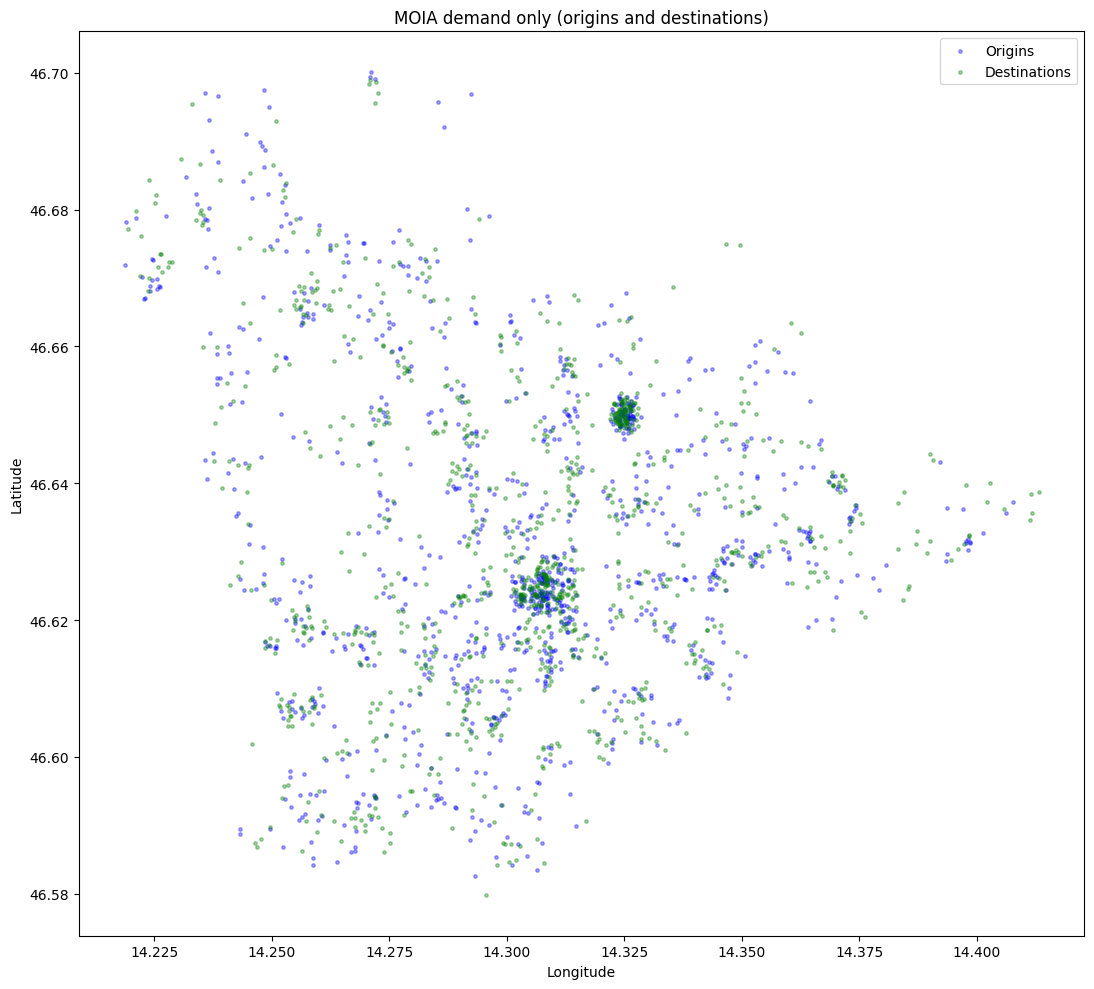

In [ ]:
# MOIA demand only (no zones)
origins_3857 = origins.to_crs(epsg=3857)
destinations_3857 = destinations.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 10))
origins_3857.plot(ax=ax, markersize=6, color="blue", alpha=0.35, label="Origins")
destinations_3857.plot(ax=ax, markersize=6, color="green", alpha=0.35, label="Destinations")

if HAS_CONTEXTILY:
    cx.add_basemap(ax, source=cx.providers.OpenStreetMap.Mapnik, alpha=0.5)

ax.set_title("MOIA demand only (origins and destinations)")
ax.set_axis_off()
ax.legend()
plt.tight_layout()
plt.show()

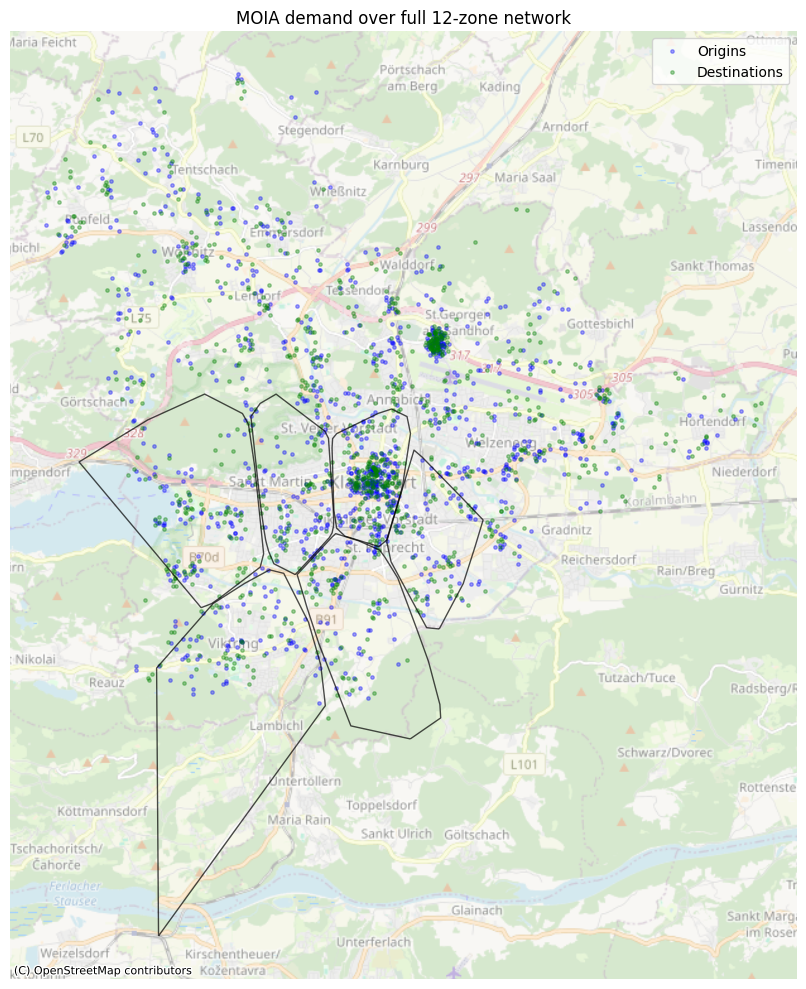

In [4]:
# Full 12-zone map with MOIA demand
full_polys_3857 = full_polys.to_crs(epsg=3857)
origins_3857 = origins.to_crs(epsg=3857)
destinations_3857 = destinations.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 10))
full_polys_3857.boundary.plot(ax=ax, linewidth=1, color="black", alpha=0.7)
origins_3857.plot(ax=ax, markersize=6, color="blue", alpha=0.35, label="Origins")
destinations_3857.plot(ax=ax, markersize=6, color="green", alpha=0.35, label="Destinations")

if HAS_CONTEXTILY:
    cx.add_basemap(ax, source=cx.providers.OpenStreetMap.Mapnik, alpha=0.5)

ax.set_title("MOIA demand over full 12-zone network")
ax.set_axis_off()
ax.legend()
plt.tight_layout()
plt.show()

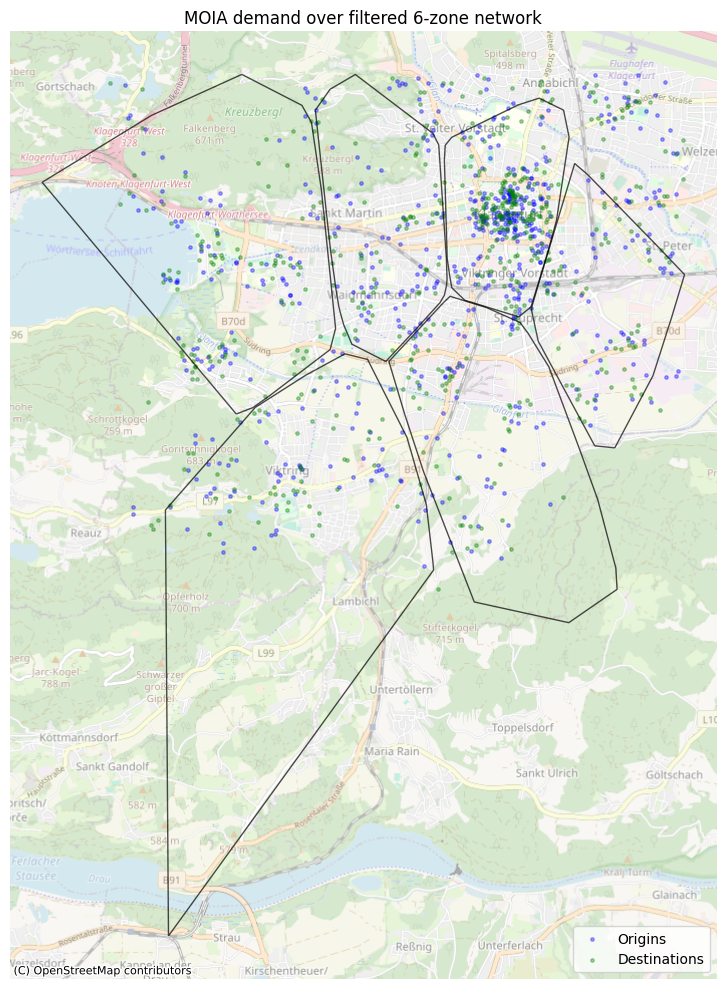

In [5]:
# Filtered 6-zone map with MOIA demand (restricted to filtered bbox)
filtered_polys_3857 = filtered_polys.to_crs(epsg=3857)

minx, miny, maxx, maxy = filtered_polys_3857.total_bounds
origins_f = origins_3857.cx[minx:maxx, miny:maxy]
destinations_f = destinations_3857.cx[minx:maxx, miny:maxy]

fig, ax = plt.subplots(figsize=(12, 10))
filtered_polys_3857.boundary.plot(ax=ax, linewidth=1, color="black", alpha=0.7)
origins_f.plot(ax=ax, markersize=6, color="blue", alpha=0.35, label="Origins")
destinations_f.plot(ax=ax, markersize=6, color="green", alpha=0.35, label="Destinations")

if HAS_CONTEXTILY:
    cx.add_basemap(ax, source=cx.providers.OpenStreetMap.Mapnik, alpha=0.5)

ax.set_title("MOIA demand over filtered 6-zone network")
ax.set_axis_off()
ax.legend()
plt.tight_layout()
plt.show()